# NumCompute 2.2: streaming decision tree demo

This notebook goes through the full streaming workflow:

1. Load data/sensor_stream.csv with the package's own CSV reader (numcompute_stream.io).
2. Split it into chunks so it acts like a stream of data.
3. Train a Pipeline (one-hot, then fill missing values, then scale, then a buffered decision tree) one chunk at a time with partial_fit(). StreamTrainer tests the model on each chunk first and then trains on it.
4. Log the metrics over time, plot them with numcompute_stream.visualise, and compare different buffer_size values.

The data is a made-up stream of machine faults (6000 rows). It has missing values, a category column where the category "D" only shows up after row 3000, and a drift at row 3500 where the rule for faults changes. You can make it again with python data/make_dataset.py.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd().parent if Path.cwd().name == "demo" else Path.cwd()
sys.path.insert(0, str(ROOT))

from numcompute_stream import io, visualise as vis
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import OneHotEncoder, SimpleImputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.stats import StreamingSummary
from numcompute_stream.metrics import StreamingAccuracy, StreamingErrorRate, StreamingF1, StreamingAUC

DATA = ROOT / "data" / "sensor_stream.csv"
CHUNK_SIZE = 100
BUFFER_SIZE = 500
DRIFT_CHUNK = 3500 // CHUNK_SIZE

## 1. Load the CSV with numcompute_stream.io

In [2]:
data = io.load_csv(DATA, target="fault", categorical=["machine_type"])
X, y = data.X, data.y
print("X shape:", X.shape, "| y shape:", y.shape)
print("features:", data.feature_names)
print("categorical column indices:", data.categorical_idx)
num = X[:, :5].astype(float)
print("missing values per numeric column:", np.isnan(num).sum(axis=0))
print("class balance:", {int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))})

X shape: (6000, 6) | y shape: (6000,)
features: ['temperature', 'pressure', 'humidity', 'vibration', 'voltage', 'machine_type']
categorical column indices: [5]
missing values per numeric column: [179 167 182 201 156]
class balance: {0: 3879, 1: 2121}


### Running statistics on the raw number columns
StreamingSummary.update_stats adds each chunk to a running mean and variance, a random sample for quantiles, and histograms. The full dataset is never needed at once.

In [3]:
summary = StreamingSummary(quantiles=(0.25, 0.5, 0.75), bins=20)
for X_chunk, _ in io.iter_array_chunks(num, chunk_size=CHUNK_SIZE):
    summary.update_stats(X_chunk)
r = summary.result()
print(f"{'feature':<12}{'count':>7}{'mean':>10}{'std':>9}{'median':>9}")
for j, name in enumerate(data.feature_names[:5]):
    print(f"{name:<12}{int(r['count'][j]):>7}{r['mean'][j]:>10.2f}{r['std'][j]:>9.2f}{r['quantiles'][0.5][j]:>9.2f}")
print("matches np.nanmean:", np.allclose(r["mean"], np.nanmean(num, axis=0)))

feature       count      mean      std   median
temperature    5821     69.95     8.03    70.07
pressure       5833     29.93     5.05    29.79
humidity       5818     50.25    17.35    50.38
vibration      5799      3.02     2.13     2.56
voltage        5844    230.03     4.02   230.01
matches np.nanmean: True


## 2. Split into chunks so it acts like a stream

In [4]:
stream = list(io.iter_array_chunks(X, y, chunk_size=CHUNK_SIZE))
print(f"{len(stream)} chunks of {CHUNK_SIZE} rows; first chunk X shape = {stream[0][0].shape}")

60 chunks of 100 rows; first chunk X shape = (100, 6)


## 3. Training one chunk at a time with partial_fit()

Pipeline steps: OneHotEncoder (adds new categories as they appear, always as new columns at the end, so earlier columns never move), then SimpleImputer (fills gaps with running means), then StandardScaler (running mean and variance), then DecisionTreeClassifier(max_depth=6, buffer_size=500).

The tree adds each chunk to its buffer. Once the buffer holds 500 samples or more, it trains a new tree from scratch on the buffer and then empties it. Between retrains, predictions come from the last tree. StreamTrainer.process_chunk tests the model on each chunk before training on it.

In [5]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("onehot", OneHotEncoder(columns=data.categorical_idx)),
        ("impute", SimpleImputer(strategy="mean", allow_growth=True)),
        ("scale",  StandardScaler(allow_growth=True)),
        ("tree",   DecisionTreeClassifier(max_depth=6, min_samples_leaf=5,
                                          buffer_size=buffer_size, random_state=0)),
    ])

pipe = make_pipeline(BUFFER_SIZE)
trainer = StreamTrainer(pipe, classes=[0, 1], metrics={
    "rolling_acc": StreamingAccuracy(window=5),
    "error_rate":  StreamingErrorRate(),
    "f1":          StreamingF1(average="binary", pos_label=1),
    "auc":         StreamingAUC(pos_label=1),
})

for i, (X_chunk, y_chunk) in enumerate(stream):
    rec = trainer.process_chunk(X_chunk, y_chunk)      # score_chunk, then fit_chunk
    if i % 10 == 0 or i == len(stream) - 1:
        print(f"chunk {i:2d} | chunk acc {rec['chunk_accuracy']:.3f} | cum acc "
              f"{rec['cumulative_accuracy']:.3f} | buffer {rec['buffer_count']:3d} | "
              f"retrains {rec['n_retrains']} | mem {rec['memory_bytes']/1024:6.1f} KB")

hist = trainer.history
summ = trainer.summary()
for k, v in summ.items():
    print(f"{k:>28}: {v:.4f}" if isinstance(v, float) else f"{k:>28}: {v}")

chunk  0 | chunk acc nan | cum acc nan | buffer 100 | retrains 0 | mem    7.7 KB
chunk 10 | chunk acc 0.850 | cum acc 0.870 | buffer 100 | retrains 2 | mem   11.1 KB
chunk 20 | chunk acc 0.880 | cum acc 0.881 | buffer 100 | retrains 4 | mem   10.4 KB
chunk 30 | chunk acc 0.930 | cum acc 0.876 | buffer 100 | retrains 6 | mem   11.7 KB
chunk 40 | chunk acc 0.830 | cum acc 0.817 | buffer 100 | retrains 8 | mem   12.5 KB
chunk 50 | chunk acc 0.810 | cum acc 0.818 | buffer 100 | retrains 10 | mem   12.7 KB
chunk 59 | chunk acc 0.860 | cum acc 0.821 | buffer   0 | retrains 12 | mem    4.5 KB
                       model: DecisionTreeClassifier
                      chunks: 60
   final_cumulative_accuracy: 0.8205
         mean_chunk_accuracy: 0.8205
              total_fit_time: 0.0554
                  n_retrains: 12
          total_retrain_time: 0.0406
           peak_memory_bytes: 36977
                 rolling_acc: 0.8260
                  error_rate: 0.1795
                          f1: 

## 4. Metrics over time

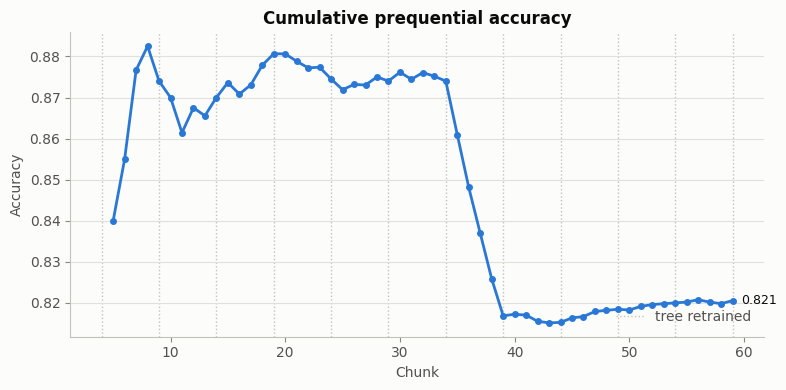

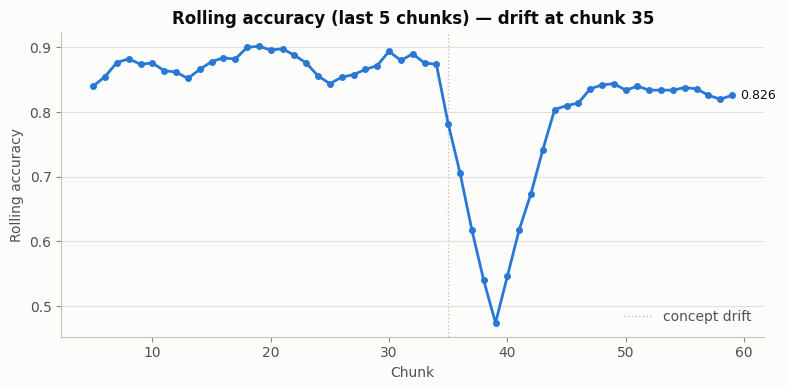

In [6]:
retrain_chunks = [i for i in range(1, len(hist["n_retrains"]))
                  if hist["n_retrains"][i] > hist["n_retrains"][i - 1]]
retrain_chunks = ([0] if hist["n_retrains"][0] else []) + retrain_chunks

vis.plot_metric_over_time(hist["cumulative_accuracy"], title="Cumulative prequential accuracy",
                          ylabel="Accuracy", events=retrain_chunks, event_label="tree retrained")
vis.plot_metric_over_time(hist["rolling_acc"],
                          title=f"Rolling accuracy (last 5 chunks) — drift at chunk {DRIFT_CHUNK}",
                          ylabel="Rolling accuracy", events=[DRIFT_CHUNK], event_label="concept drift")
plt.show()

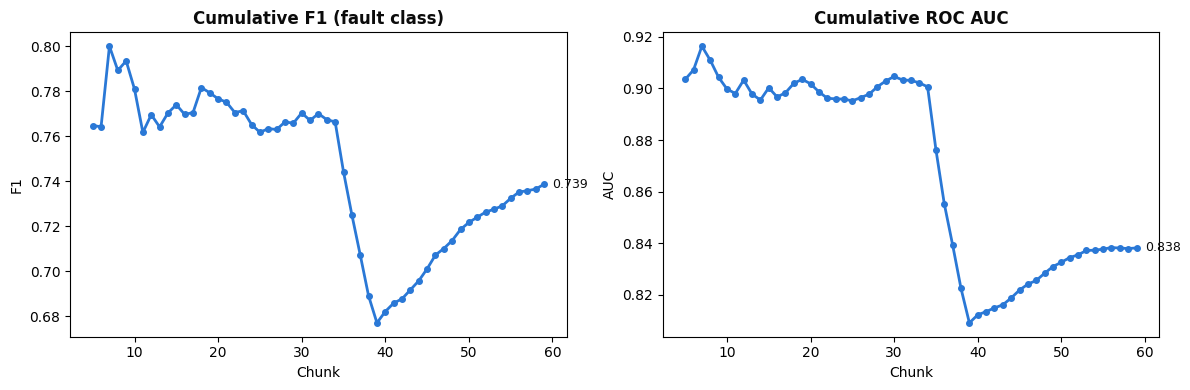

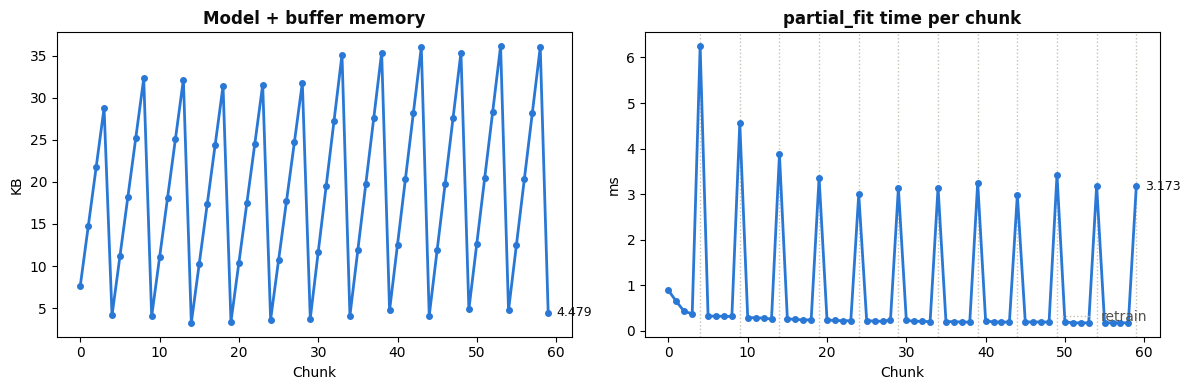

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
vis.plot_metric_over_time(hist["f1"], title="Cumulative F1 (fault class)", ylabel="F1", ax=axes[0])
vis.plot_metric_over_time(hist["auc"], title="Cumulative ROC AUC", ylabel="AUC", ax=axes[1])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
vis.plot_metric_over_time(np.array(hist["memory_bytes"]) / 1024, title="Model + buffer memory",
                          ylabel="KB", ax=axes[0])
vis.plot_metric_over_time(np.array(hist["fit_time"]) * 1e3, title="partial_fit time per chunk",
                          ylabel="ms", events=retrain_chunks, event_label="retrain", ax=axes[1])
plt.show()

The memory line goes up and down like a saw: it grows as the buffer fills and drops when a retrain empties it. partial_fit time only jumps on retrain chunks. The rest of the time, adding to the buffer takes almost no time.

## 5. Comparing models: buffer_size=250 and buffer_size=2000

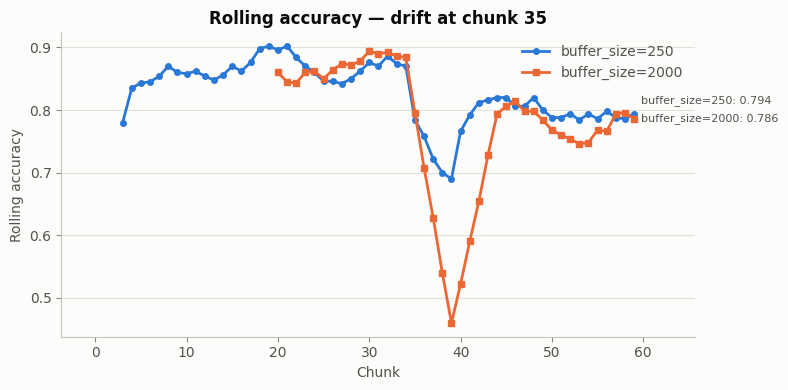

buffer_size= 250: cumulative acc 0.828, retrains 20, total retrain time 32.2 ms
buffer_size=2000: cumulative acc 0.774, retrains 3, total retrain time 28.1 ms


In [8]:
results = {}
for b in (250, 2000):
    t = StreamTrainer(make_pipeline(b), classes=[0, 1],
                      metrics={"rolling_acc": StreamingAccuracy(window=5)})
    t.run(stream)
    results[b] = t

vis.compare_models(results[250].history["rolling_acc"], results[2000].history["rolling_acc"],
                   labels=["buffer_size=250", "buffer_size=2000"],
                   title=f"Rolling accuracy — drift at chunk {DRIFT_CHUNK}", ylabel="Rolling accuracy")
plt.show()
for b, t in results.items():
    s = t.summary()
    print(f"buffer_size={b:4d}: cumulative acc {s['final_cumulative_accuracy']:.3f}, "
          f"retrains {s['n_retrains']}, total retrain time {s['total_retrain_time']*1e3:.1f} ms")

A small buffer starts predicting after a few chunks and recovers quickly after the drift, but each tree learns from less data. A large buffer gives each tree more data, but it takes a long time before the first prediction and reacts slowly to the drift (it keeps using the old tree until the buffer fills again). See benchmark/stream_results.md for all the buffer sizes tested.

## 6. Predictions and true labels on the last chunk

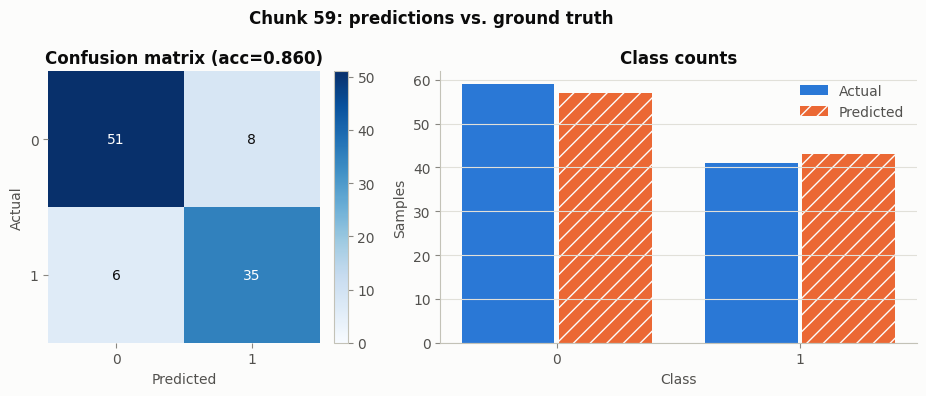

In [9]:
vis.plot_predictions_vs_ground_truth(trainer.last_y_true_, trainer.last_y_pred_,
                                     title=f"Chunk {len(stream) - 1}: predictions vs. ground truth")
plt.show()

## 7. Look at the current tree

In [10]:
tree = pipe["tree"]
names = pipe["onehot"].get_feature_names(data.feature_names)
print(f"depth={tree.get_depth()}, nodes={tree.n_nodes}, leaves={tree.n_leaves}, "
      f"trained on {tree.n_node_samples_[0]} samples")
imp = tree.feature_importances_
for j in np.argsort(imp)[::-1][:5]:
    print(f"  {names[j]:<16} {imp[j]:.3f}")
print()
print("\n".join(tree.export_text(names).splitlines()[:12]), "\n...")

depth=6, nodes=59, leaves=30, trained on 500 samples
  pressure         0.423
  humidity         0.268
  temperature      0.226
  machine_type=D   0.054
  machine_type=B   0.014

pressure <= -0.159
|   humidity <= 0.568
|   |   temperature <= -1.425
|   |   |   pressure <= -0.576
|   |   |   |   class: 0 (n=8)
|   |   |   pressure >  -0.576
|   |   |   |   class: 1 (n=5)
|   |   temperature >  -1.425
|   |   |   pressure <= -0.267
|   |   |   |   machine_type=A <= 1.159
|   |   |   |   |   temperature <= -0.81
|   |   |   |   |   |   class: 0 (n=7) 
...


After the drift, the latest tree mostly uses pressure and humidity, which matches the rule the data generator uses after the drift. Before the drift (the first trees) it used temperature and vibration, so retraining from the buffer has followed the change.

## 8. Saving figures
Every plot function takes save_path= (PNG, SVG or PDF) and show=:

In [11]:
out = ROOT / "demo" / "figures"
out.mkdir(exist_ok=True)
fig, _ = vis.plot_metric_over_time(hist["cumulative_accuracy"], title="Cumulative accuracy",
                                   ylabel="Accuracy", save_path=out / "cumulative_accuracy.png")
plt.close(fig)
print("saved:", sorted(p.name for p in out.iterdir()))

saved: ['cumulative_accuracy.png']
